# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhamad Reyvan Lukni Maolana
- NIM   : 241011400610
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library yang diizinkan untuk implementasi utama
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 10
np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (7, 4)


In [2]:
# Pembagian data manual, mengikuti pola dari materi dosen.
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)
    if not 0 < test_size < 1:
        raise ValueError("test_size harus di antara 0 dan 1.")
    if len(X) != len(y):
        raise ValueError("Jumlah baris X dan y harus sama.")
    n_test = int(round(len(X) * test_size))
    rng = np.random.RandomState(random_state) if random_state is not None else np.random
    indices = rng.permutation(len(X))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# Model Linear Regression dengan Normal Equation, diadaptasi dari materi.
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None
    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Gradient Descent; nilai loss non-finite tetap dicatat sebagai bukti divergensi.
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate, self.n_iterations = learning_rate, n_iterations
        self.intercept_, self.coefficients_ = 0.0, None
        self.loss_history_, self.beta_history_, self.diverged_ = [], [], False
    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        with np.errstate(over='ignore', invalid='ignore'):
            for _ in range(self.n_iterations):
                y_hat = X_b @ beta
                gradient = X_b.T @ (y_hat - y) / len(y)
                beta = beta - self.learning_rate * gradient
                loss = np.mean((y - X_b @ beta) ** 2)
                if not np.all(np.isfinite(beta)) or not np.isfinite(loss):
                    self.diverged_ = True
                    self.loss_history_.append(np.inf if np.isinf(loss) else np.nan)
                    self.beta_history_.append(beta.copy())
                    break
                self.loss_history_.append(float(loss))
                self.beta_history_.append(beta.copy())
        if self.diverged_:
            self.intercept_, self.coefficients_ = np.nan, np.full(X.shape[1], np.nan)
            # Pad to the requested iteration count so plots use consistent iteration indices.
            self.loss_history_ += [np.nan] * (self.n_iterations - len(self.loss_history_))
        else:
            self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Logistic Regression biner dengan gradient descent, mengikuti materi.
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate, self.n_iterations = learning_rate, n_iterations
        self.intercept_, self.coefficients_ = 0.0, None
        self.loss_history_ = []
    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta -= self.learning_rate * gradient
            p_updated = np.clip(self._sigmoid(X_b @ beta), 1e-15, 1 - 1e-15)
            self.loss_history_.append(float(-np.mean(y*np.log(p_updated) + (1-y)*np.log(1-p_updated))))
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# Metrik klasifikasi buatan sendiri, tanpa scikit-learn.
def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))
def confusion_matrix(y_true, y_pred):
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    return np.array([[np.sum((yt==0)&(yp==0)), np.sum((yt==0)&(yp==1))],
                     [np.sum((yt==1)&(yp==0)), np.sum((yt==1)&(yp==1))]])
def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp/(tp+fp) if tp+fp else 0.0
def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tp/(tp+fn) if tp+fn else 0.0
def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2*p*r/(p+r) if p+r else 0.0


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


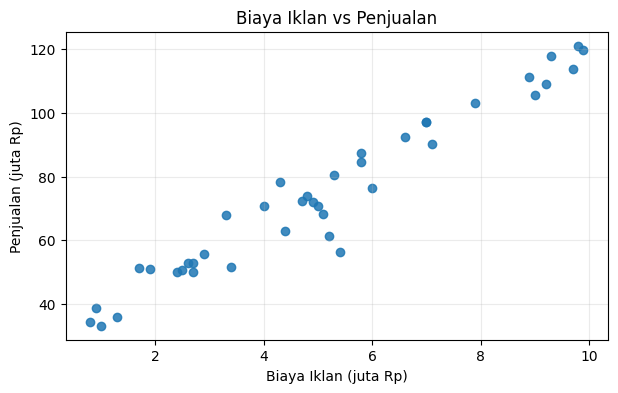

In [3]:
# Jawaban A1
ads_data = pd.read_csv('Ads_Data.csv')
display(ads_data.head())
print(f'Jumlah baris data: {len(ads_data)}')
X = ads_data[['BiayaIklan']].to_numpy(dtype=float)
y = ads_data['Penjualan'].to_numpy(dtype=float)
print('Shape X:', X.shape, '| Shape y:', y.shape)
plt.scatter(X[:, 0], y, alpha=0.85)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.25)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
regressor = LinearRegression().fit(X_train, y_train)
b_linear = float(regressor.intercept_)
m_linear = float(regressor.coefficients_[0])
print(f'Intercept (b): {b_linear:.4f}')
print(f'Koefisien (m): {m_linear:.4f}')
print(f'Persamaan regresi: ŷ = {b_linear:.4f} + ({m_linear:.4f} × BiayaIklan)')


Intercept (b): 29.3864
Koefisien (m): 9.0711
Persamaan regresi: ŷ = 29.3864 + (9.0711 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Koefisien biaya iklan menunjukkan perubahan rata-rata penjualan yang diperkirakan untuk setiap kenaikan biaya iklan sebesar Rp1 juta per bulan. Berdasarkan koefisien hasil training di atas, penjualan diperkirakan berubah sekitar nilai koefisien tersebut (dalam juta rupiah), dengan asumsi hubungan linear pada rentang data ini.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))
def mse(y_true, y_pred):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_pred))**2))
def rmse(y_true, y_pred):
    return float(np.sqrt(mse(y_true, y_pred)))
def r2_score(y_true, y_pred):
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((yt-yp)**2)
    ss_tot = np.sum((yt-np.mean(yt))**2)
    return float(1-ss_res/ss_tot) if ss_tot else float('nan')

y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)
regression_metrics = pd.DataFrame([
    {'Data':'Training','MAE':mae(y_train,y_train_pred),'MSE':mse(y_train,y_train_pred),
     'RMSE':rmse(y_train,y_train_pred),'R²':r2_score(y_train,y_train_pred)},
    {'Data':'Testing','MAE':mae(y_test,y_test_pred),'MSE':mse(y_test,y_test_pred),
     'RMSE':rmse(y_test,y_test_pred),'R²':r2_score(y_test,y_test_pred)}
]).set_index('Data')
display(regression_metrics.round(4))


,MAE,MSE,RMSE,R²
Data,,,,
Training,3.7920,24.4404,4.9437,0.9618
Testing,7.2023,87.1316,9.3344,0.8464


**Jawaban A4 (analisis):**

RMSE menunjukkan besarnya kesalahan prediksi tipikal dalam satuan penjualan (juta rupiah); semakin kecil semakin baik. R² menunjukkan proporsi variasi penjualan yang dapat dijelaskan model, dan nilai yang mendekati 1 umumnya menunjukkan kecocokan yang lebih baik. Bandingkan hasil training dengan testing: jika testing lebih buruk, model mungkin kurang mampu menggeneralisasi. Kesimpulan akhir mengikuti angka tabel di atas, bukan hanya nilai training.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Learning rate,Intercept,Koefisien,Loss awal,Loss akhir,Status
0,0.001,20.150382,10.484470,5964.672833,43.398146,Selesai
1,0.020,29.386389,9.071079,789.965872,24.440353,Selesai
2,0.100,NaN,NaN,37141.745574,NaN,Divergen


Normal Equation: intercept=29.386389, koefisien=9.071079


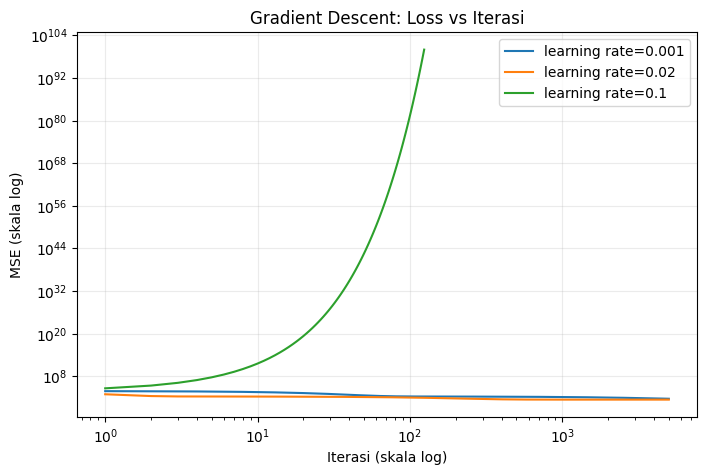

In [7]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []
for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model_gd
    gd_rows.append({
        'Learning rate': lr,
        'Intercept': model_gd.intercept_,
        'Koefisien': model_gd.coefficients_[0],
        'Loss awal': model_gd.loss_history_[0],
        'Loss akhir': model_gd.loss_history_[-1],
        'Status': 'Divergen' if model_gd.diverged_ else 'Selesai'
    })
display(pd.DataFrame(gd_rows).round(6))
print(f'Normal Equation: intercept={b_linear:.6f}, koefisien={m_linear:.6f}')
plt.figure(figsize=(8, 5))
for lr, model_gd in gd_models.items():
    losses = np.asarray(model_gd.loss_history_, dtype=float)
    valid = np.isfinite(losses) & (losses > 0) & (losses < 1e100)
    if valid.any():
        plt.plot(np.arange(1, len(losses)+1)[valid], losses[valid], label=f'learning rate={lr}')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Iterasi (skala log)')
plt.ylabel('MSE (skala log)')
plt.title('Gradient Descent: Loss vs Iterasi')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


**Jawaban A5 (analisis):**

Learning rate menentukan besar langkah pembaruan parameter. Learning rate kecil biasanya belajar lebih lambat, sedangkan nilai yang terlalu besar dapat melewati titik minimum sehingga loss meningkat atau menjadi tidak hingga (divergen). Perhatikan status, loss, dan grafik eksperimen di atas; parameter yang divergen tidak dapat dibandingkan sebagai hasil konvergen dengan Normal Equation. Karena fitur tidak dinormalisasi, learning rate yang tampak besar bisa tidak stabil.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

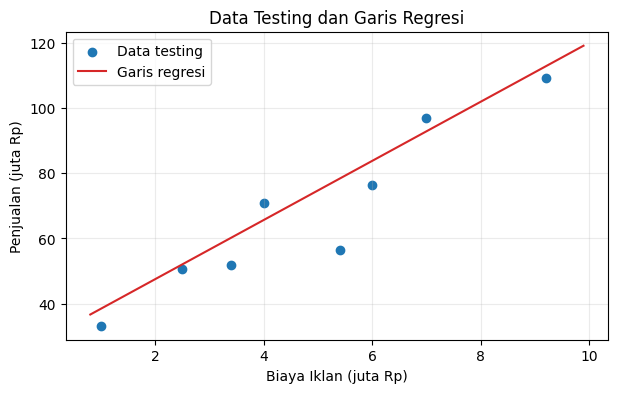

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,70.206
1,7.0,92.884
2,12.0,138.239


In [8]:
# Jawaban A6
order = np.argsort(X_test[:, 0])
plt.scatter(X_test[:, 0], y_test, label='Data testing', color='tab:blue')
x_line = np.linspace(float(X.min()), float(X.max()), 200).reshape(-1, 1)
plt.plot(x_line[:, 0], regressor.predict(x_line), color='tab:red', label='Garis regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

nilai_iklan = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = regressor.predict(nilai_iklan)
prediksi_ads = pd.DataFrame({'BiayaIklan (juta Rp)': nilai_iklan[:,0],
                             'Prediksi Penjualan (juta Rp)': prediksi_penjualan})
display(prediksi_ads.round(3))


**Jawaban A6 (analisis):**

Prediksi 4,5 dan 7 juta berada dekat rentang biaya iklan yang terlihat pada data sehingga lebih didukung oleh pengamatan. Prediksi pada 12 juta merupakan ekstrapolasi karena melampaui nilai maksimum data yang tersedia. Karena pola hubungan di luar rentang pengamatan belum teruji dan faktor lain juga memengaruhi penjualan, prediksi 12 juta perlu dianggap lebih tidak pasti.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email: 60
Jumlah kelas (0 = Bukan Spam, 1 = Spam):


,Jumlah
Spam,
Bukan Spam (0),35
Spam (1),25


Shape X: (60, 2) | Shape y: (60,)


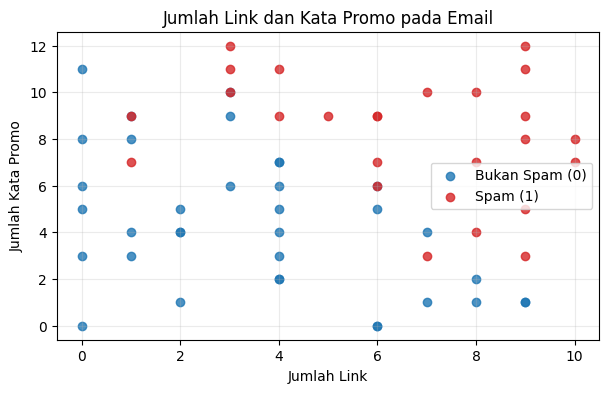

In [9]:
# Jawaban B1
email_data = pd.read_csv('Email_Data.csv')
display(email_data.head())
print('Jumlah email:', len(email_data))
print('Jumlah kelas (0 = Bukan Spam, 1 = Spam):')
display(email_data['Spam'].value_counts().sort_index().rename(index={0:'Bukan Spam (0)',1:'Spam (1)'}).to_frame('Jumlah'))
X_email = email_data[['JumlahLink', 'KataPromo']].to_numpy(dtype=float)
y_email = email_data['Spam'].to_numpy(dtype=int)
print('Shape X:', X_email.shape, '| Shape y:', y_email.shape)
plt.scatter(X_email[y_email==0,0], X_email[y_email==0,1], c='tab:blue', label='Bukan Spam (0)', alpha=0.8)
plt.scatter(X_email[y_email==1,0], X_email[y_email==1,1], c='tab:red', label='Spam (1)', alpha=0.8)
plt.title('Jumlah Link dan Kata Promo pada Email')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | y_train: (45,)
X_test : (15, 2) | y_test : (15,)


Intercept (b): -11.191095
Koefisien m1 (JumlahLink): 1.026407
Koefisien m2 (KataPromo): 0.877795
P(Spam) = sigmoid(-11.191095 + (1.026407 × JumlahLink) + (0.877795 × KataPromo))


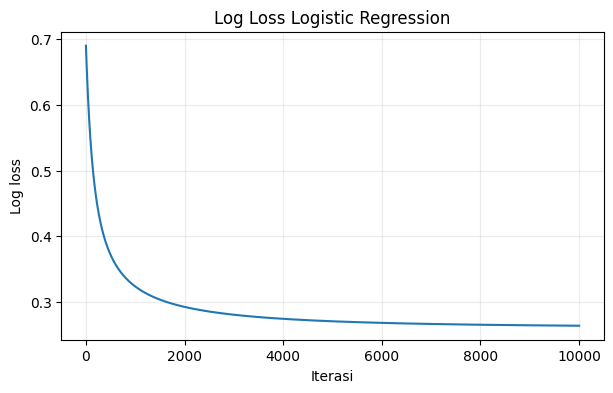

Log loss awal: 0.690241
Log loss akhir: 0.263808


In [10]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print('X_train:', X_train_email.shape, '| y_train:', y_train_email.shape)
print('X_test :', X_test_email.shape, '| y_test :', y_test_email.shape)
classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train_email, y_train_email)
b_log = float(classifier.intercept_)
m1_log, m2_log = classifier.coefficients_
print(f'Intercept (b): {b_log:.6f}')
print(f'Koefisien m1 (JumlahLink): {m1_log:.6f}')
print(f'Koefisien m2 (KataPromo): {m2_log:.6f}')
print(f'P(Spam) = sigmoid({b_log:.6f} + ({m1_log:.6f} × JumlahLink) + ({m2_log:.6f} × KataPromo))')
plt.plot(np.arange(1, len(classifier.loss_history_)+1), classifier.loss_history_)
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.title('Log Loss Logistic Regression')
plt.grid(alpha=0.25)
plt.show()
print(f'Log loss awal: {classifier.loss_history_[0]:.6f}')
print(f'Log loss akhir: {classifier.loss_history_[-1]:.6f}')


**Jawaban B2 (analisis):**

Model Logistic Regression memetakan kombinasi jumlah link dan kata promo menjadi probabilitas spam melalui sigmoid. Jika grafik menunjukkan log loss menurun lalu mendatar, artinya pembaruan parameter mulai stabil. Nilai koefisien menunjukkan arah hubungan masing-masing fitur dengan probabilitas spam ketika fitur lain dianggap tetap; interpretasinya didasarkan pada parameter yang tercetak di atas.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
y_proba_test = classifier.predict_proba(X_test_email)
y_pred_email = (y_proba_test >= 0.5).astype(int)
cm_email = confusion_matrix(y_test_email, y_pred_email)
tn, fp, fn, tp = cm_email.ravel()
metrics_email = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test_email, y_pred_email),
    'Precision': precision_score(y_test_email, y_pred_email),
    'Recall': recall_score(y_test_email, y_pred_email),
    'F1-score': f1_score(y_test_email, y_pred_email)
}])
print('Confusion matrix (baris = aktual [0,1], kolom = prediksi [0,1]):')
display(pd.DataFrame(cm_email, index=['Aktual Bukan Spam (0)','Aktual Spam (1)'],
                     columns=['Prediksi Bukan Spam (0)','Prediksi Spam (1)']))
display(metrics_email.round(4))
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')


Confusion matrix (baris = aktual [0,1], kolom = prediksi [0,1]):


,Prediksi Bukan Spam (0),Prediksi Spam (1)
Aktual Bukan Spam (0),5,0
Aktual Spam (1),1,9


,Accuracy,Precision,Recall,F1-score
0,0.9333,1.0,0.9,0.9474


TN=5, FP=0, FN=1, TP=9


**Jawaban B3 (analisis):**

FP adalah email bukan spam yang keliru ditandai sebagai spam; akibatnya email penting dapat masuk folder spam. FN adalah email spam yang keliru dianggap bukan spam sehingga tetap masuk kotak masuk. Kerugian bergantung pada kebutuhan pengguna: FP dapat membuat pesan penting terlewat, sedangkan FN membuat spam lolos. Untuk filter email umum, saya cenderung mengutamakan mengurangi FP agar email sah tidak salah dibuang, sambil tetap memantau recall.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-11.191095 + (1.026407 × JumlahLink)) / (0.877795)


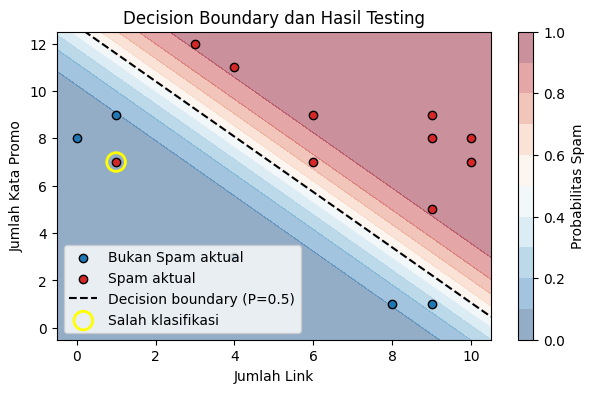

Jumlah salah klasifikasi: 1


,JumlahLink,KataPromo,Aktual,Prediksi
0,1.0,7.0,1,0


In [12]:
# Jawaban B4
if abs(m2_log) > 1e-12:
    print(f'Decision boundary: KataPromo = -({b_log:.6f} + ({m1_log:.6f} × JumlahLink)) / ({m2_log:.6f})')
    x1_vals = np.linspace(X_email[:,0].min()-0.5, X_email[:,0].max()+0.5, 250)
    x2_vals = np.linspace(X_email[:,1].min()-0.5, X_email[:,1].max()+0.5, 250)
    xx1, xx2 = np.meshgrid(x1_vals, x2_vals)
    grid_email = np.c_[xx1.ravel(), xx2.ravel()]
    prob_grid = classifier.predict_proba(grid_email).reshape(xx1.shape)
    plt.contourf(xx1, xx2, prob_grid, levels=np.linspace(0,1,11), cmap='RdBu_r', alpha=0.45)
    plt.colorbar(label='Probabilitas Spam')
    plt.scatter(X_test_email[y_test_email==0,0], X_test_email[y_test_email==0,1], c='tab:blue', edgecolors='k', label='Bukan Spam aktual')
    plt.scatter(X_test_email[y_test_email==1,0], X_test_email[y_test_email==1,1], c='tab:red', edgecolors='k', label='Spam aktual')
    boundary_y = -(b_log + m1_log*x1_vals)/m2_log
    plt.plot(x1_vals, boundary_y, 'k--', label='Decision boundary (P=0.5)')
    wrong = y_pred_email != y_test_email
    plt.scatter(X_test_email[wrong,0], X_test_email[wrong,1], s=180, facecolors='none', edgecolors='yellow', linewidths=2, label='Salah klasifikasi')
    plt.xlabel('Jumlah Link')
    plt.ylabel('Jumlah Kata Promo')
    plt.title('Decision Boundary dan Hasil Testing')
    plt.ylim(x2_vals.min(), x2_vals.max())
    plt.legend()
    plt.show()
    wrong_rows = pd.DataFrame(X_test_email[wrong], columns=['JumlahLink','KataPromo'])
    wrong_rows['Aktual'] = y_test_email[wrong]
    wrong_rows['Prediksi'] = y_pred_email[wrong]
    print('Jumlah salah klasifikasi:', int(wrong.sum()))
    display(wrong_rows)
else:
    print('Koefisien KataPromo mendekati nol, sehingga garis tidak dapat ditulis dalam bentuk x2 = ...')


**Jawaban B4 (analisis):**

Decision boundary adalah garis tempat probabilitas prediksi spam sama dengan 0,5. Titik yang dilingkari kuning pada grafik merupakan email testing yang kelas prediksinya berbeda dari label aktual; tabel di bawah grafik menampilkan fitur, label aktual, dan prediksinya. Kualitas pemisahan perlu dinilai bersama metrik testing, bukan hanya dari bentuk grafik.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred_thr = (y_proba_test >= threshold).astype(int)
    threshold_predictions[threshold] = pred_thr
    cm_thr = confusion_matrix(y_test_email, pred_thr)
    threshold_rows.append({
        'Threshold': threshold,
        'TN': cm_thr[0,0], 'FP': cm_thr[0,1],
        'FN': cm_thr[1,0], 'TP': cm_thr[1,1],
        'Precision': precision_score(y_test_email, pred_thr),
        'Recall': recall_score(y_test_email, pred_thr)
    })
threshold_results = pd.DataFrame(threshold_rows).set_index('Threshold')
display(threshold_results.round(4))
# Pilih threshold 0.3 untuk memprioritaskan recall/mengurangi spam yang lolos.
THRESHOLD_PILIHAN = 0.3
print('Threshold yang digunakan pada prediksi email baru:', THRESHOLD_PILIHAN)


,TN,FP,FN,TP,Precision,Recall
Threshold,,,,,,
0.3,5,0,1,9,1.0,0.9
0.5,5,0,1,9,1.0,0.9
0.7,5,0,1,9,1.0,0.9


Threshold yang digunakan pada prediksi email baru: 0.3


**Jawaban B5 (analisis):**

Secara umum, threshold lebih rendah membuat model lebih mudah memberi label spam sehingga recall dapat naik, tetapi FP juga dapat bertambah dan precision bisa turun. Threshold lebih tinggi cenderung mengurangi prediksi spam, yang bisa menaikkan precision tetapi menurunkan recall. Pada data testing ini, ketiga threshold (0,3; 0,5; 0,7) menghasilkan confusion matrix dan precision/recall yang sama (TN=5, FP=0, FN=1, TP=9; precision=1,0; recall=0,9), sehingga tidak ada perbedaan hasil pada sampel testing ini. Saya memilih threshold 0,3 untuk lebih memprioritaskan menangkap spam, namun hasil ini tidak menjamin performa yang sama pada data baru.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
email_baru = pd.DataFrame({
    'Email': ['E1','E2','E3','E4'],
    'JumlahLink': [1,5,9,2],
    'KataPromo': [2,6,10,11]
})
X_baru = email_baru[['JumlahLink','KataPromo']].to_numpy(dtype=float)
email_baru['Probabilitas Spam'] = classifier.predict_proba(X_baru)
email_baru['Prediksi kelas'] = (email_baru['Probabilitas Spam'] >= THRESHOLD_PILIHAN).astype(int)
email_baru['Keterangan'] = email_baru['Prediksi kelas'].map({0:'Bukan Spam',1:'Spam'})
display(email_baru.round(4))


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi kelas,Keterangan
0,E1,1,2,0.0002,0,Bukan Spam
1,E2,5,6,0.3117,1,Spam
2,E3,9,10,0.9989,1,Spam
3,E4,2,11,0.6266,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena hasil akhirnya digunakan untuk menentukan kelas, misalnya spam atau bukan spam, bukan untuk memperkirakan nilai kontinu. Model menghitung kombinasi linear fitur terlebih dahulu, lalu sigmoid mengubahnya menjadi probabilitas antara 0 dan 1. Dengan threshold tertentu, probabilitas itu diubah menjadi label kelas 0 atau 1.

**Jawaban C2:**

Normal Equation menghitung koefisien Linear Regression langsung melalui operasi matriks sehingga tidak memerlukan iterasi. Gradient Descent memulai dari parameter awal lalu memperbaruinya berulang kali berdasarkan gradien loss. Gradient Descent berguna ketika data atau jumlah fitur sangat besar sehingga perhitungan langsung matriks menjadi mahal, tetapi hasilnya dipengaruhi learning rate dan jumlah iterasi.

**Jawaban C3:**

Data training dipakai untuk mempelajari parameter model, jadi nilai evaluasi pada data itu bisa terlihat terlalu bagus. Data testing digunakan untuk mengukur kemampuan model pada data yang tidak ikut dipakai saat training. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training dan performanya menurun pada data baru.

**Jawaban C4:**

Linear Regression menghasilkan nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai prediksi dan nilai sebenarnya. Logistic Regression menghasilkan probabilitas untuk kelas, sehingga log loss menilai seberapa baik probabilitas tersebut cocok dengan label 0 atau 1. Log loss memberi penalti besar ketika model sangat yakin pada probabilitas yang salah.

**Jawaban C5:**

Hasil dapat berbeda karena pembagian training dan testing yang berbeda menghasilkan data pelatihan yang berbeda. Nilai random state mengatur pembagian tersebut. Pada Gradient Descent, learning rate, jumlah iterasi, skala fitur, dan parameter awal juga memengaruhi hasil akhir. Perbedaan implementasi atau pengaturan regularisasi juga dapat membuat koefisien dan metrik tidak sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# Linear Regression: data training dan testing sama dengan implementasi manual.
sk_linear = SklearnLinearRegression().fit(X_train, y_train)
sk_linear_train_pred = sk_linear.predict(X_train)
sk_linear_test_pred = sk_linear.predict(X_test)
linear_bonus = pd.DataFrame([
    {'Model':'Manual - Normal Equation','Intercept':b_linear,'Koefisien':m_linear,
     'Train RMSE':rmse(y_train, regressor.predict(X_train)),
     'Test RMSE':rmse(y_test, regressor.predict(X_test)),
     'Test R²':r2_score(y_test, regressor.predict(X_test))},
    {'Model':'scikit-learn LinearRegression','Intercept':float(sk_linear.intercept_),'Koefisien':float(sk_linear.coef_[0]),
     'Train RMSE':rmse(y_train, sk_linear_train_pred),
     'Test RMSE':rmse(y_test, sk_linear_test_pred),
     'Test R²':r2_score(y_test, sk_linear_test_pred)}
])
print('Perbandingan Linear Regression:')
display(linear_bonus.round(6))

# Logistic Regression scikit-learn dengan konfigurasi eksplisit; C=1 dan L2 adalah default umum.
sk_log = SklearnLogisticRegression(C=1.0, solver='lbfgs', max_iter=10000, random_state=RANDOM_STATE)
sk_log.fit(X_train_email, y_train_email)
sk_log_pred = sk_log.predict(X_test_email)
manual_pred = classifier.predict(X_test_email)
log_bonus = pd.DataFrame([
    {'Model':'Manual - Gradient Descent','Intercept':classifier.intercept_,
     'Koefisien JumlahLink':classifier.coefficients_[0],
     'Koefisien KataPromo':classifier.coefficients_[1],
     'Accuracy testing':accuracy_score(y_test_email,manual_pred),
     'Precision testing':precision_score(y_test_email,manual_pred),
     'Recall testing':recall_score(y_test_email,manual_pred),
     'F1 testing':f1_score(y_test_email,manual_pred)},
    {'Model':'scikit-learn LogisticRegression','Intercept':float(sk_log.intercept_[0]),
     'Koefisien JumlahLink':float(sk_log.coef_[0,0]),
     'Koefisien KataPromo':float(sk_log.coef_[0,1]),
     'Accuracy testing':accuracy_score(y_test_email,sk_log_pred),
     'Precision testing':precision_score(y_test_email,sk_log_pred),
     'Recall testing':recall_score(y_test_email,sk_log_pred),
     'F1 testing':f1_score(y_test_email,sk_log_pred)}
])
print('Perbandingan Logistic Regression (evaluasi pada threshold default 0.5):')
display(log_bonus.round(6))
print('Confusion matrix manual:\n', confusion_matrix(y_test_email, manual_pred))
print('Confusion matrix scikit-learn:\n', confusion_matrix(y_test_email, sk_log_pred))


Perbandingan Linear Regression:


,Model,Intercept,Koefisien,Train RMSE,Test RMSE,Test R²
0,Manual - Normal Equation,29.386389,9.071079,4.943719,9.334432,0.846418
1,scikit-learn LinearRegression,29.386389,9.071079,4.943719,9.334432,0.846418


Perbandingan Logistic Regression (evaluasi pada threshold default 0.5):


,Model,Intercept,Koefisien JumlahLink,Koefisien KataPromo,Accuracy testing,Precision testing,Recall testing,F1 testing
0,Manual - Gradient Descent,-11.191095,1.026407,0.877795,0.933333,1.0,0.9,0.947368
1,scikit-learn LogisticRegression,-10.497928,0.953672,0.824176,0.933333,1.0,0.9,0.947368


Confusion matrix manual:
 [[5 0]
 [1 9]]
Confusion matrix scikit-learn:
 [[5 0]
 [1 9]]


**Jawaban Bonus (analisis):**

Linear Regression manual dengan Normal Equation dan scikit-learn LinearRegression seharusnya menghasilkan koefisien serta prediksi yang hampir sama karena keduanya meminimalkan jumlah kuadrat error tanpa regularisasi. Logistic Regression scikit-learn dapat berbeda karena secara default menggunakan regularisasi L2 (parameter `C` mengatur kebalikan kekuatan regularisasi), sedangkan implementasi manual di atas tidak memakai regularisasi. Selain itu, optimisasi dan kriteria berhentinya berbeda. Karena itu, perbandingan harus melihat koefisien dan metrik testing yang benar-benar tercetak pada tabel, bukan menganggap hasilnya pasti identik.